In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [59]:
df=pd.read_csv("/Users\Samanpreet Kaur\Desktop\cbitss\datasets\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [60]:
df.shape

(7043, 21)

In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [62]:
print("missing:", df.isna().sum().sum(),
      "| duplicate rows:", df.duplicated().sum(),
      "| duplicate IDs:", df.customerID.duplicated().sum())

missing: 0 | duplicate rows: 0 | duplicate IDs: 0


In [63]:
df['customerID'].duplicated().sum()

np.int64(0)

In [64]:
#I checked data quality first. There were no missing values, no duplicate rows, and no duplicate customer IDs.

In [65]:
#TotalCharges was stored as text because new customers with 0 months of tenure had blank values. I replaced those with 0 and converted the column to float.
df['TotalCharges']=df["TotalCharges"].replace(" ","0")
df['TotalCharges']=df["TotalCharges"].astype("float")


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [67]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [68]:
#describe() shows an average tenure of about 32 months, an average monthly charge of about $65, and tenure ranging from 0 to 72 months.

In [69]:
#I converted SeniorCitizen from 0/1 to No/Yes so the charts read clearly.
df["SeniorCitizen"]=df["SeniorCitizen"].astype("str")
df["SeniorCitizen"]=df["SeniorCitizen"].replace("0","No")
df["SeniorCitizen"]=df["SeniorCitizen"].replace("1","Yes")


In [70]:
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [71]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

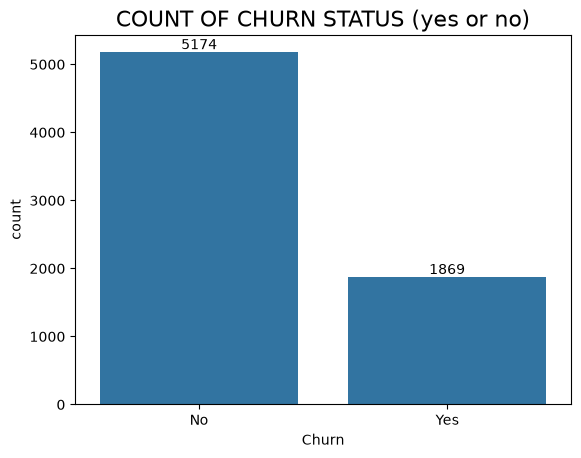

In [72]:
ax1=sns.countplot(x='Churn',data=df)
ax1.bar_label(ax1.containers[0])
ax1.set_title('COUNT OF CHURN STATUS (yes or no)',size=16)
plt.show()

In [73]:
gb=df.groupby('Churn').agg({'Churn':'count'})
gb

,Churn
Churn,
No,5174
Yes,1869


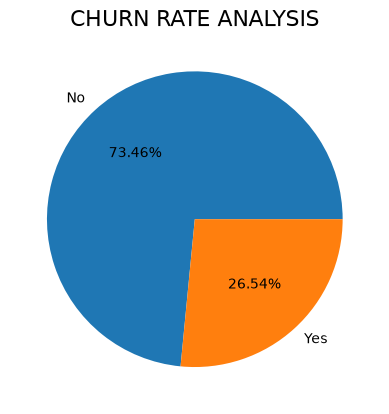

In [74]:
plt.pie(gb['Churn'],labels=gb.index,autopct="%1.2f%%")
plt.title('CHURN RATE ANALYSIS',size=16)
plt.show()

In [75]:
#Churn count and pie chart:
#1.Of 7,043 customers, 1,869 churned and 5,174 stayed. That is a churn rate of about 26.5%, or roughly 1 in 4 customers."
#2.The dataset is imbalanced, with far more retained customers than churned ones. This matters if I build a prediction model later.

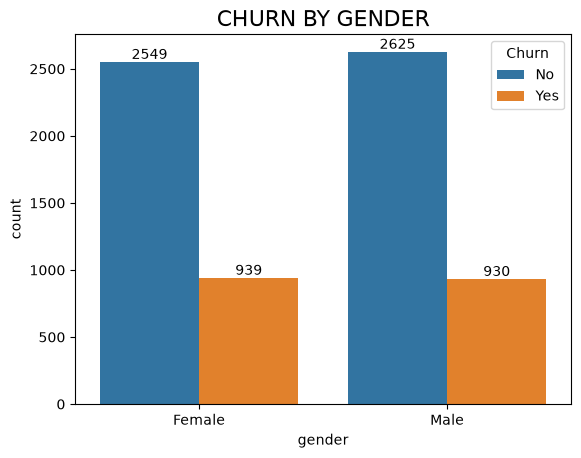

In [76]:
ax2=sns.countplot(x='gender',data=df,hue="Churn")
for container in ax2.containers:
    ax2.bar_label(container)
plt.title("CHURN BY GENDER",size=16)
plt.show()

In [77]:
#"Churn is almost identical for females (939) and males (930), at about 27% vs 26%. Gender is not a meaningful driver of churn."

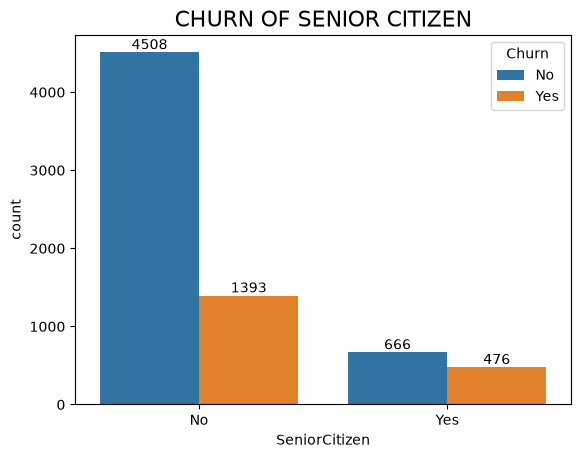

In [78]:
ax2=sns.countplot(x='SeniorCitizen',data=df,hue="Churn")
for container in ax2.containers:
    ax2.bar_label(container)
plt.title("CHURN OF SENIOR CITIZEN",size=16)
plt.show()

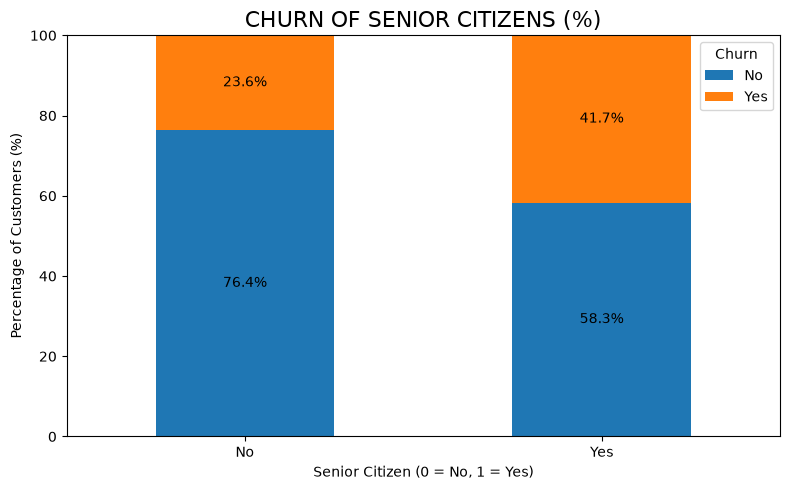

In [79]:
df_percent = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

ax2 = df_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)
for container in ax2.containers:
    labels = [
        f'{bar.get_height():.1f}%' if bar.get_height() > 0 else ''
        for bar in container
    ]
    ax2.bar_label(container, labels=labels, label_type='center')

plt.title("CHURN OF SENIOR CITIZENS (%)", size=16)
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [80]:
#"Senior citizens churn at 41.7%, compared with 23.6% for non-seniors. The percentage chart is more reliable here because seniors are a much smaller group, so raw counts alone would hide this gap."

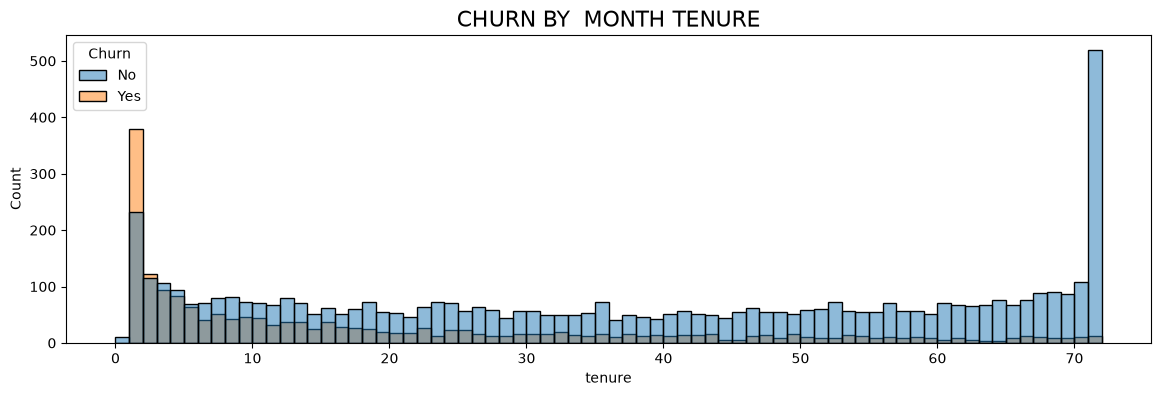

In [81]:
plt.figure(figsize=(14,4))
ax3=sns.histplot(x='tenure',data=df,bins=72,hue='Churn')
plt.title('CHURN BY  MONTH TENURE',size=16)
plt.show()

In [82]:
#Churn is concentrated in the first few months. The tallest churn spike is at month 1, and it falls steadily as tenure increases.
#Long-tenure customers, especially those near 72 months, rarely leave. The early months are the critical retention window.

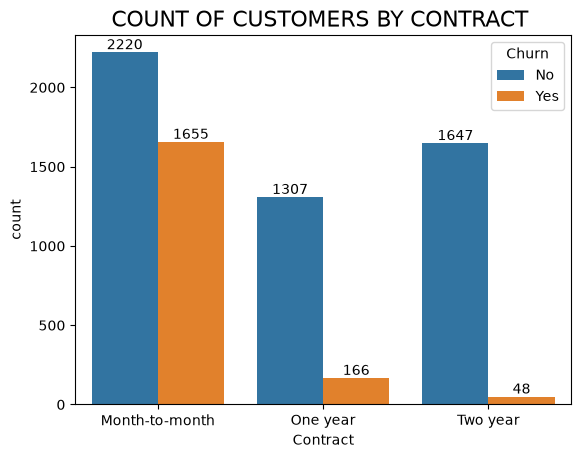

In [83]:
ax4=sns.countplot(x='Contract',data=df,hue='Churn')
for container in ax4.containers:
    ax4.bar_label(container)
ax4.set_title('COUNT OF CUSTOMERS BY CONTRACT ',size=16)
plt.show()

In [84]:
#Month-to-month customers churn at about 43% (1,655 of 3,875). One-year contracts churn at about 11% and two-year contracts at under 3%.
#Contract length is one of the strongest churn indicators. Longer commitments clearly improve retention.

In [85]:
df.columns.values

<StringArray>
[      'customerID',           'gender',    'SeniorCitizen',
          'Partner',       'Dependents',           'tenure',
     'PhoneService',    'MultipleLines',  'InternetService',
   'OnlineSecurity',     'OnlineBackup', 'DeviceProtection',
      'TechSupport',      'StreamingTV',  'StreamingMovies',
         'Contract', 'PaperlessBilling',    'PaymentMethod',
   'MonthlyCharges',     'TotalCharges',            'Churn']
Length: 21, dtype: str

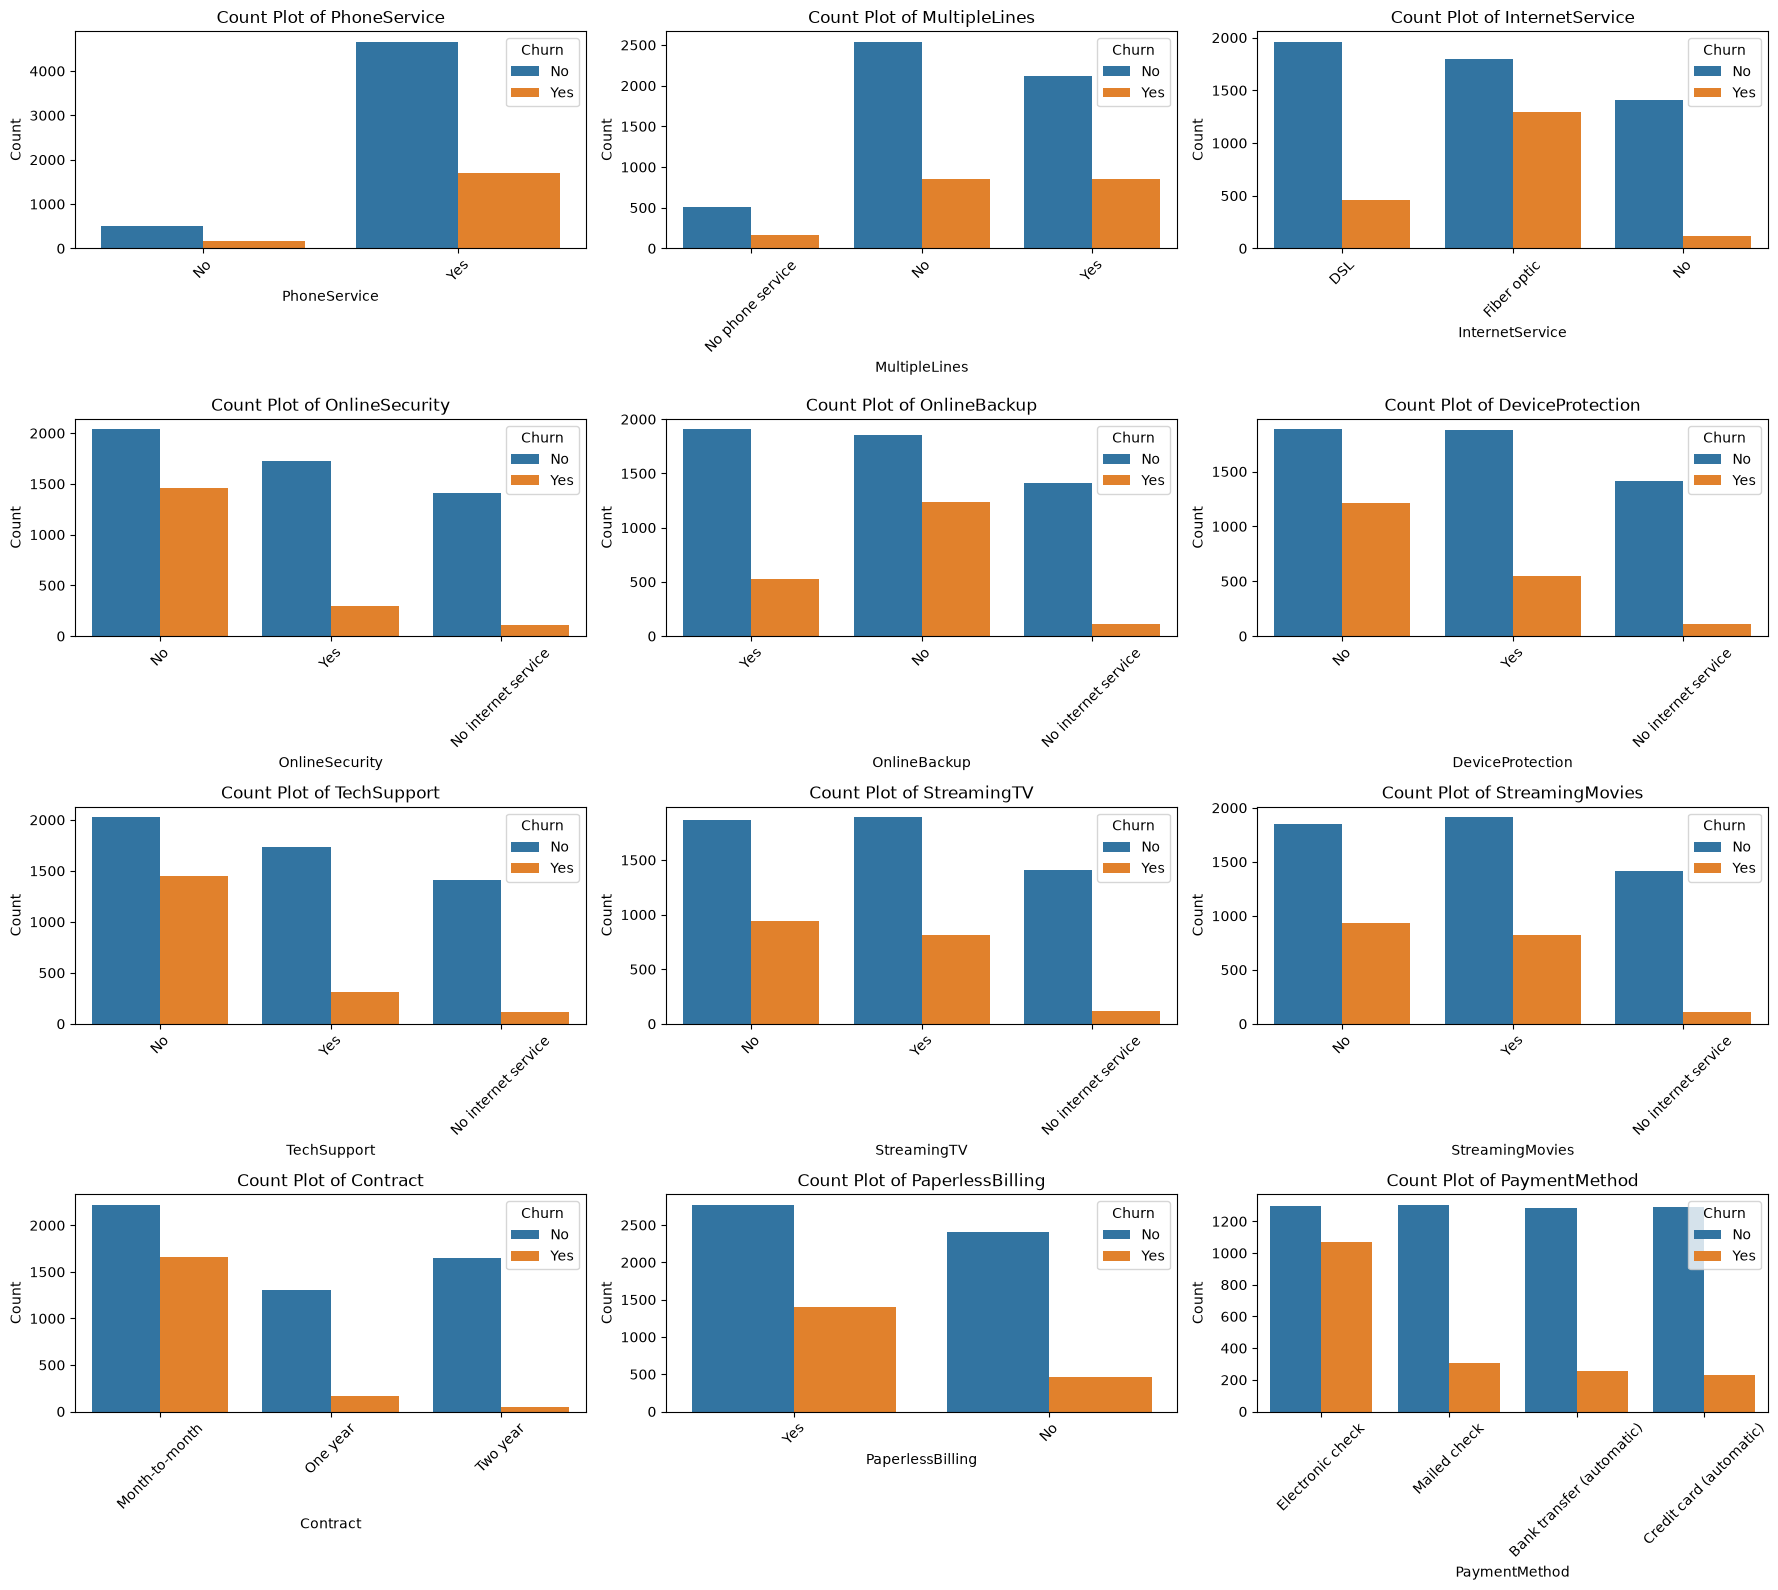

In [86]:
columns = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]
n_cols =3
n_rows = math.ceil(len(columns) / n_cols)

# Create subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

# Iterate over columns and create countplots
for i, col in enumerate(columns):
    sns.countplot(x=col, data=df, ax=axes[i],hue="Churn")
    axes[i].set_title(f'Count Plot of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

# Remove empty subplots, if any
for j in range(len(columns), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [87]:
#1. Customers using Fiber optic internet show a higher number of churn cases compared to DSL and customers without internet service.
#2. Customers with month-to-month contracts have significantly higher churn than those with one-year or two-year contracts.
#3. Customers without Online Security and Tech Support tend to have higher churn, indicating that these services may help improv customer retention.
#4. Electronic check users show the highest churn compared to customers using other payment methods.
#5. Customers with Paperless Billing and those using Phone Service also represent a substantial portion of churn, suggesting that customer service plans and billing preferences may be useful areas for further analysis.

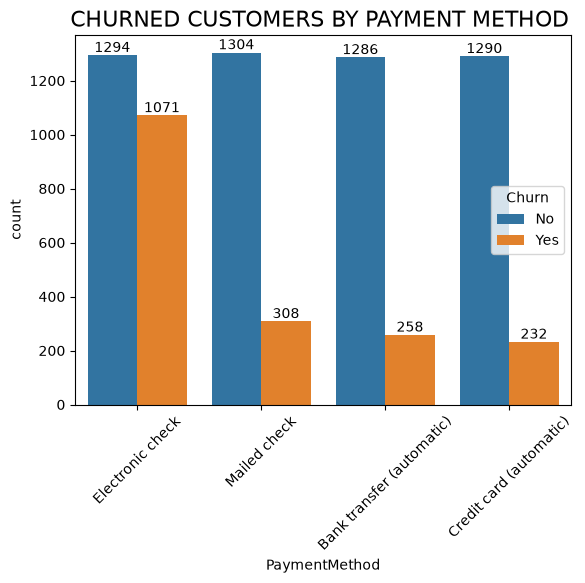

In [88]:
plt.Figure(figsize=(6,12))
ax5=sns.countplot(x='PaymentMethod',data=df,hue='Churn')
for container in ax5.containers:
    ax5.bar_label(container)
ax5.set_title('CHURNED CUSTOMERS BY PAYMENT METHOD ',size=16)
plt.xticks(rotation=45)
plt.show()

In [89]:
#"Electronic check users churn at about 45% (1,071 of 2,365). Mailed check, bank transfer, and credit card users churn at 15–19%.
#Customers on automatic payments seem more likely to stay.

In [ ]:
#Closing summary:

#The typical churner is a new customer on a month-to-month contract, using fiber optic internet, paying by electronic check, and without security or tech support add-ons. To reduce churn, the company could:

    #1.Offer incentives to move customers onto longer contracts.
    #2.Bundle security and tech support for new customers.
    #3.Encourage automatic payment methods.
    #4.Focus onboarding efforts on the first 3 months."